In [1]:
!pip install -q kagglehub
import glob, os, kagglehub
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.dpi"] = 110

path = kagglehub.dataset_download("jahaidulislam/world-happiness-report-2005-2021")
df = pd.read_csv(glob.glob(os.path.join(path, "*.csv"))[0])
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

# Fill missing values: country median, then global median
num = df.select_dtypes("number").columns.drop("year")
for c in num:
    df[c] = df.groupby("country_name")[c].transform(lambda x: x.fillna(x.median()))
    df[c] = df[c].fillna(df[c].median())

south_asia = ["Bangladesh", "India", "Pakistan", "Sri Lanka", "Nepal", "Afghanistan"]
df["region_group"] = np.where(df.country_name.isin(south_asia), "South Asia", "Rest of World")

print(df.shape)
print(df.groupby("year").country_name.nunique())

100%|██████████| 115k/115k [00:00<00:00, 30.8MB/s]

Extracting files...


(2089, 13)
year
2005     27
2006     89
2007    102
2008    110
2009    114
2010    124
2011    146
2012    142
2013    137
2014    145
2015    143
2016    142
2017    147
2018    142
2019    144
2020    116
2021    119
Name: country_name, dtype: int64


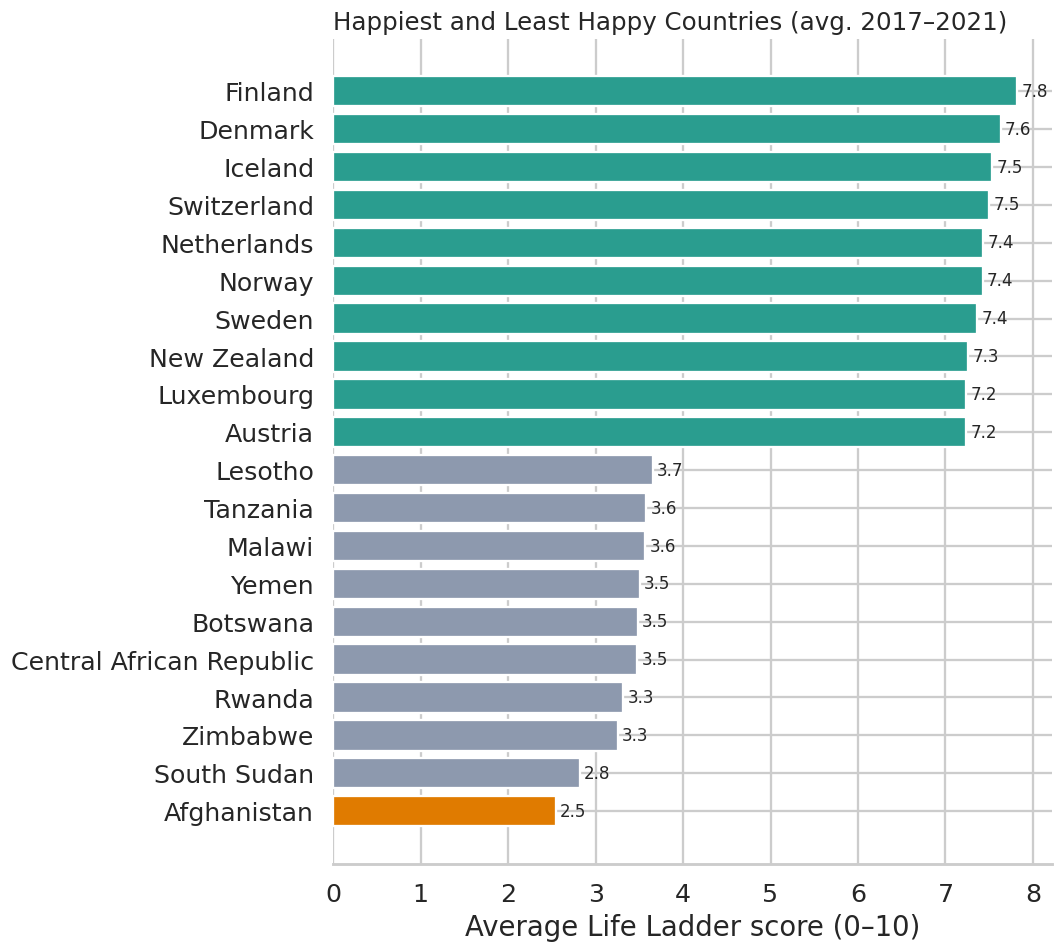

In [4]:
recent = df[df.year >= 2017].groupby("country_name").life_ladder.mean()
top10, bottom10 = recent.nlargest(10), recent.nsmallest(10)
plot_df = pd.concat([top10, bottom10]).sort_values()

colors = []
for c in plot_df.index:
    if c in south_asia: colors.append("#e07b00")      # South Asia = orange
    elif c in top10.index: colors.append("#2a9d8f")   # top 10 = green
    else: colors.append("#8d99ae")                    # bottom 10 = grey

fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(plot_df.index, plot_df.values, color=colors)
for i, v in enumerate(plot_df.values):
    ax.text(v + 0.05, i, f"{v:.1f}", va="center", fontsize=11)
ax.set_title("Happiest and Least Happy Countries (avg. 2017–2021)", fontsize=16, loc="left")
ax.set_xlabel("Average Life Ladder score (0–10)")
ax.set_ylabel("")
sns.despine(left=True)
plt.tight_layout()
plt.show()

84 countries with data in every year


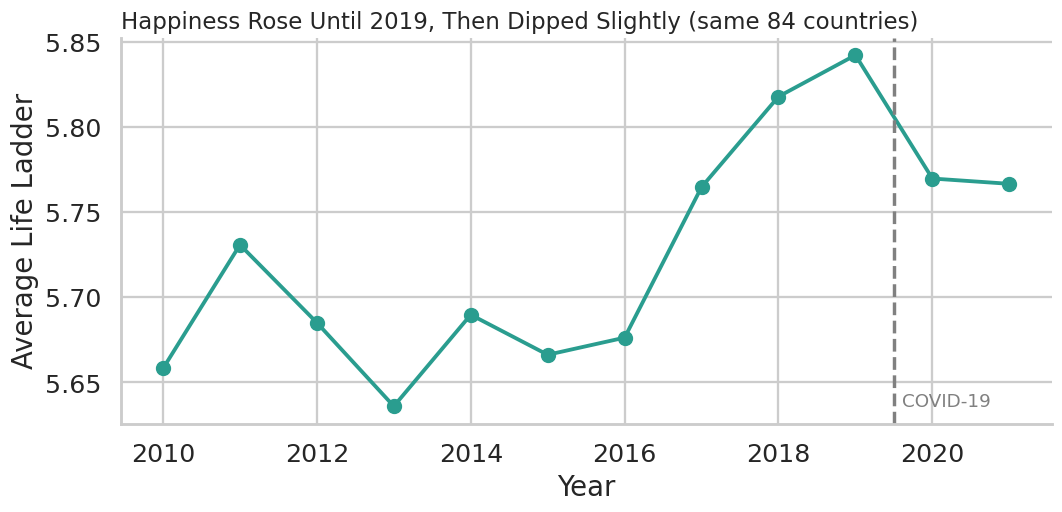

In [16]:
YEARS = range(2010, 2022)
cnt = df[df.year.isin(YEARS)].groupby("country_name").year.nunique()
full = cnt[cnt == len(YEARS)].index
panel = df[df.country_name.isin(full) & df.year.isin(YEARS)]
print(len(full), "countries with data in every year")
yearly = panel.groupby("year").life_ladder.mean()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(yearly.index, yearly.values, marker="o", color="#2a9d8f", linewidth=2.5)
ax.axvline(2019.5, color="gray", linestyle="--")
ax.text(2019.6, yearly.min(), "COVID-19", color="gray", fontsize=12)
ax.set_title(f"Average Happiness, Same {len(full)} Countries (2010–2021)", fontsize=16, loc="left")
ax.set_title(f"Happiness Rose Until 2019, Then Dipped Slightly (same {len(full)} countries)", fontsize=15, loc="left")
ax.set_xlabel("Year")
ax.set_ylabel("Average Life Ladder")
sns.despine()
plt.tight_layout()
plt.show()

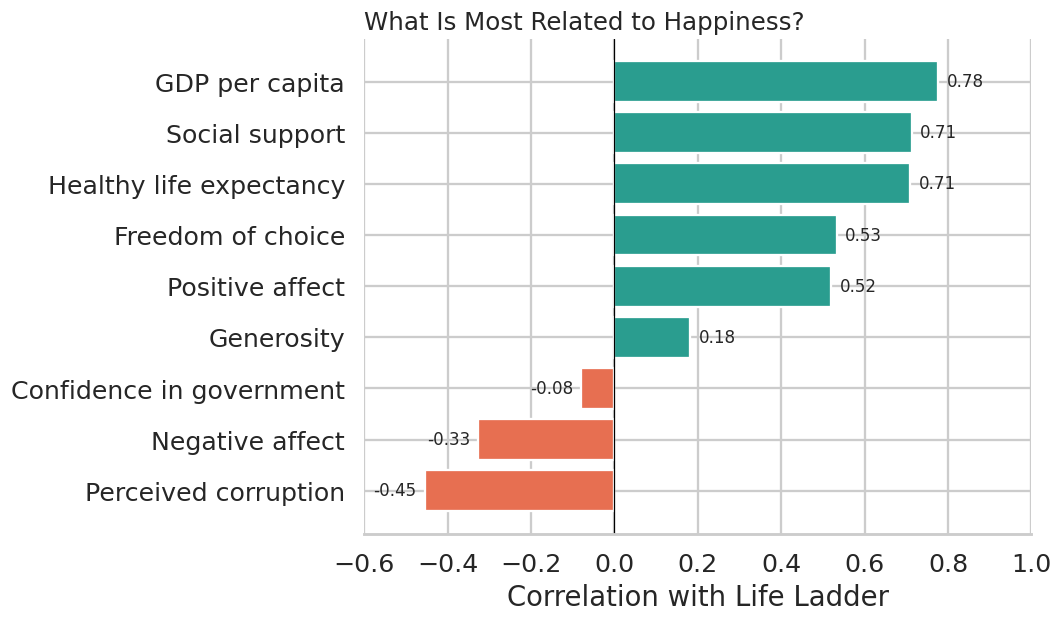

In [7]:
factors = {
    "log_gdp_per_capita": "GDP per capita",
    "social_support": "Social support",
    "healthy_life_expectancy_at_birth": "Healthy life expectancy",
    "freedom_to_make_life_choices": "Freedom of choice",
    "positive_affect": "Positive affect",
    "generosity": "Generosity",
    "confidence_in_national_government": "Confidence in government",
    "negative_affect": "Negative affect",
    "perceptions_of_corruption": "Perceived corruption",
}
corr = df[list(factors)].corrwith(df["life_ladder"]).rename(index=factors).sort_values()
colors = ["#2a9d8f" if v > 0 else "#e76f51" for v in corr]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(corr.index, corr.values, color=colors)
for i, v in enumerate(corr.values):
    ax.text(v + (0.02 if v >= 0 else -0.02), i, f"{v:.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=11)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlim(-0.6, 1)
ax.set_title("What Is Most Related to Happiness?", fontsize=16, loc="left")
ax.set_xlabel("Correlation with Life Ladder")
sns.despine(left=True)
plt.tight_layout()
plt.show()

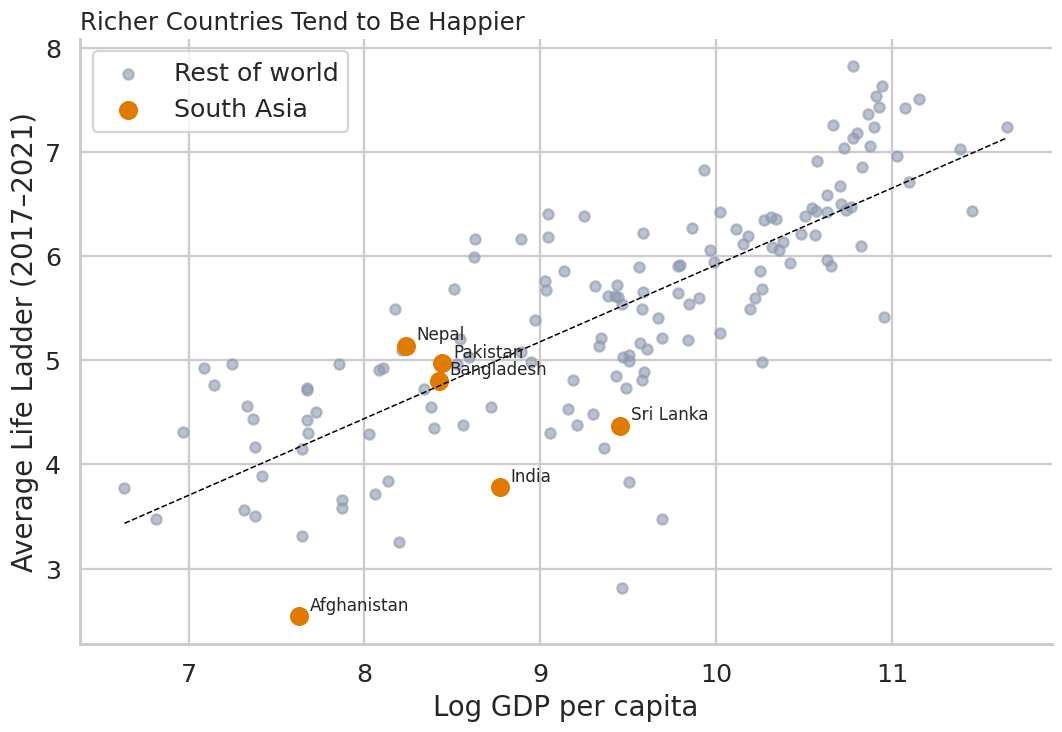

In [8]:
c = df[df.year >= 2017].groupby("country_name").agg(
    life=("life_ladder", "mean"), gdp=("log_gdp_per_capita", "mean")).reset_index()
c["sa"] = c.country_name.isin(south_asia)

fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(c[~c.sa].gdp, c[~c.sa].life, color="#8d99ae", alpha=0.6, s=45, label="Rest of world")
ax.scatter(c[c.sa].gdp, c[c.sa].life, color="#e07b00", s=120, label="South Asia")
m, b = np.polyfit(c.gdp, c.life, 1)
xs = np.linspace(c.gdp.min(), c.gdp.max(), 50)
ax.plot(xs, m * xs + b, color="black", linestyle="--", linewidth=1)
for _, r in c[c.sa].iterrows():
    ax.annotate(r.country_name, (r.gdp, r.life), xytext=(7, 4), textcoords="offset points", fontsize=11)
ax.set_title("Richer Countries Tend to Be Happier", fontsize=16, loc="left")
ax.set_xlabel("Log GDP per capita")
ax.set_ylabel("Average Life Ladder (2017–2021)")
ax.legend()
sns.despine()
plt.tight_layout()
plt.show()

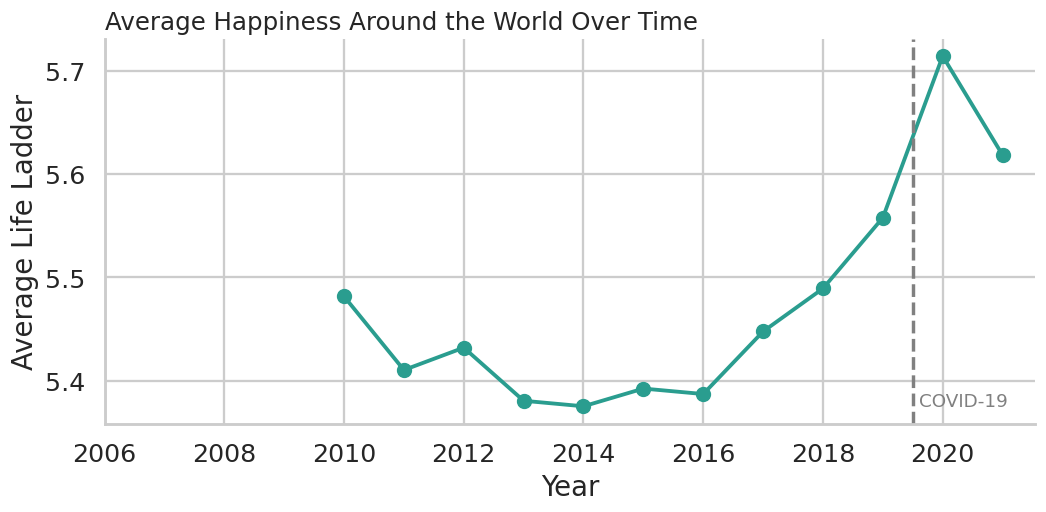

In [15]:
START = 2010   # change this after looking at the country counts in Step 1
yearly = df[df.year >= START].groupby("year").life_ladder.mean()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(yearly.index, yearly.values, marker="o", color="#2a9d8f", linewidth=2.5)
ax.axvline(2019.5, color="gray", linestyle="--")
ax.text(2019.6, yearly.min(), "COVID-19", color="gray", fontsize=12)
ax.set_title("Average Happiness Around the World Over Time", fontsize=16, loc="left")
ax.set_xlabel("Year")
ax.set_ylabel("Average Life Ladder")
ax.set_xticks(range(2006, 2022, 2))
sns.despine()
plt.tight_layout()
plt.show()

South Asian countries in this comparison: ['India', 'Nepal', 'Pakistan']


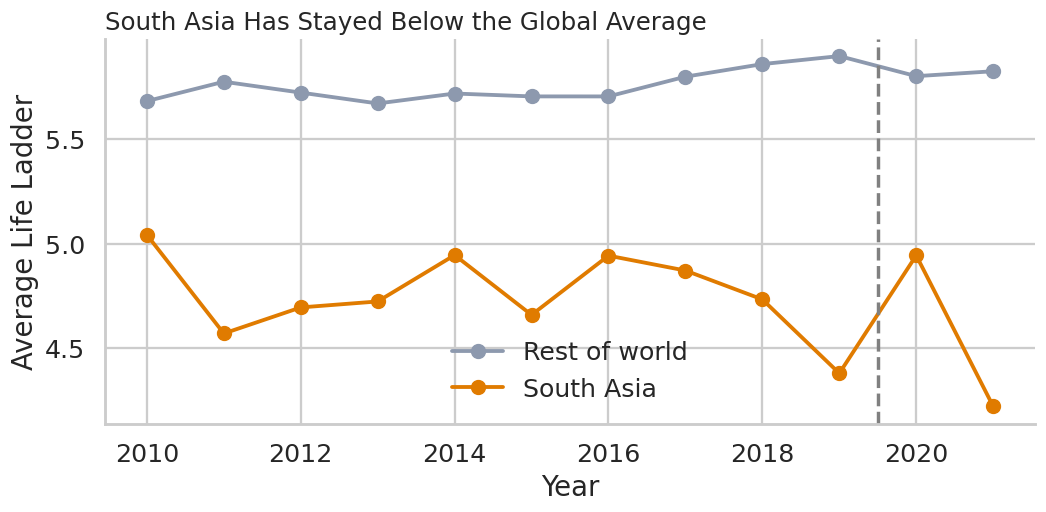

In [9]:
sa_panel = panel.groupby(["year", "region_group"]).life_ladder.mean().unstack()
print("South Asian countries in this comparison:", sorted(set(panel.country_name) & set(south_asia)))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(sa_panel.index, sa_panel["Rest of World"], color="#8d99ae", marker="o", linewidth=2.5, label="Rest of world")
ax.plot(sa_panel.index, sa_panel["South Asia"], color="#e07b00", marker="o", linewidth=2.5, label="South Asia")
ax.axvline(2019.5, color="gray", linestyle="--")
ax.set_title("India, Nepal and Pakistan Stay Below the Global Average (same countries each year)", fontsize=14, loc="left")
ax.set_xlabel("Year")
ax.set_ylabel("Average Life Ladder")
ax.legend(frameon=False)
sns.despine()
plt.tight_layout()
plt.show()

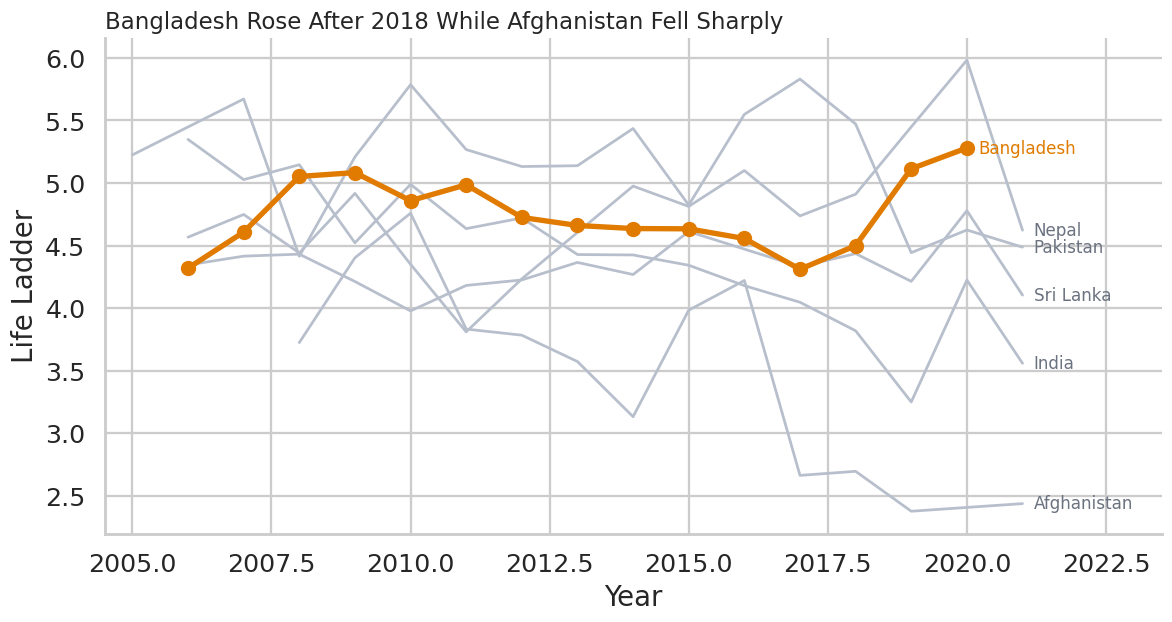

In [12]:
sa_df = df[df.country_name.isin(south_asia)]
fig, ax = plt.subplots(figsize=(11, 6))
for name, g in sa_df.groupby("country_name"):
    hl = name == "Bangladesh"
    ax.plot(g.year, g.life_ladder, color="#e07b00" if hl else "#b8bfcc",
            linewidth=3.5 if hl else 1.8, marker="o" if hl else None, zorder=3 if hl else 1)
    last = g.iloc[-1]
    ax.text(last.year + 0.2, last.life_ladder, name, fontsize=11,
            color="#e07b00" if hl else "#6b7280", va="center")
ax.set_xlim(2004.5, 2023.5)
ax.set_title("Bangladesh Rose After 2018 While Afghanistan Fell Sharply", fontsize=15, loc="left")
ax.set_xlabel("Year")
ax.set_ylabel("Life Ladder")
sns.despine()
plt.tight_layout()
plt.show()